# CardioIA Fase 4: Parte 1, pré-processamento e organização das imagens

**Curso:** Inteligência Artificial, FIAP, turma 2TIAOR, Fase 4, Cap 1 (Visão Computacional na Clínica)
**Autor:** Silvio Prestes Guerreiro Junior, RM 567958

> **Aviso:** protótipo acadêmico, sem validade diagnóstica. Usa apenas dados públicos e anonimizados. Nenhum resultado deste notebook deve orientar conduta clínica.

## Objetivo

Preparar um conjunto de radiografias de tórax para treinar redes convolucionais que distinguem **Cardiomegalia** (aumento da silhueta cardíaca) de **Sem achado**. O notebook cobre os itens da Parte 1 do enunciado:

1. seleção de um dataset público de imagens médicas;
2. redimensionamento, normalização e conversão de formatos;
3. criação dos conjuntos de treino, validação e teste;
4. documentação de cada etapa do pipeline, com a justificativa das escolhas.

A execução gravada aqui foi feita em máquina local (Apple M5, Python 3.12). O notebook usa o módulo `src/nih_remoto.py` e as pastas deste repositório, portanto no Google Colab ele precisa dos arquivos do repositório na máquina do Colab. Nessa condição ele foi executado no Colab em 20/11/2026, com Python 3.13, e gerou o mesmo manifesto e as mesmas imagens processadas (registro em `docs/teste_colab_2026-11-20.md`).

## 1. Configuração

Sementes fixas e caminhos relativos garantem que a execução se repita com o mesmo resultado. As imagens originais (cerca de 2,5 GB) ficam em uma pasta de cache fora do repositório, definida pela variável de ambiente `CARDIOIA_RAW`. As imagens já processadas (224 x 224) ficam em `data/processed/`.

In [1]:
import os, sys, json, random, hashlib
from pathlib import Path

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from PIL import Image

SEED = 42
random.seed(SEED); np.random.seed(SEED)

EM_COLAB = "google.colab" in sys.modules
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()   # pasta cardioia-fase4
sys.path.insert(0, str(RAIZ / "src"))

DIR_META  = RAIZ / "data" / "raw"                 # metadados (CSV)
DIR_PROC  = RAIZ / "data" / "processed"           # imagens 224x224 em treino/val/teste
DIR_PRINT = RAIZ / "prints"                       # figuras para o relatório
DIR_RAW   = Path(os.environ.get("CARDIOIA_RAW", RAIZ / "data" / "raw" / "imagens_originais"))
for d in (DIR_META, DIR_PROC, DIR_PRINT, DIR_RAW): d.mkdir(parents=True, exist_ok=True)

IMG_SIZE = 224                                    # entrada padrão de VGG16, ResNet50 e MobileNetV2
CLASSES  = ["sem_achado", "cardiomegalia"]        # índice 0 = negativa, 1 = positiva
FRACOES  = {"train": 0.70, "val": 0.15, "test": 0.15}

print("Colab:", EM_COLAB, "| raiz:", RAIZ.name, "| python:", sys.version.split()[0])
print("numpy", np.__version__, "| pandas", pd.__version__, "| opencv", cv2.__version__)

Colab: False | raiz: cardioia-fase4 | python: 3.12.13
numpy 2.5.5 | pandas 3.1.1 | opencv 5.0.0


## 2. Seleção do dataset

**Dataset:** NIH Chest X-ray (ChestX-ray14), do NIH Clinical Center, o mesmo citado no enunciado.

| Item | Valor |
|---|---|
| Imagens | 112.120 radiografias frontais de tórax, PNG 1024 x 1024 |
| Pacientes | 30.805, anonimizados |
| Rótulos | 14 achados extraídos de laudos por processamento de linguagem natural, mais "No Finding". Uma imagem pode ter vários rótulos |
| Metadados | idade, sexo, posição de aquisição (PA ou AP), número de acompanhamento |
| Tamanho | cerca de 42 GB |
| Licença | uso sem restrições, com atribuição ao NIH Clinical Center e citação de Wang et al. (2017) |
| Fonte usada | espelho público no Hugging Face (`alkzar90/NIH-Chest-X-ray-dataset`), que replica os arquivos originais |

**Por que este dataset:** é público, anonimizado, tem um achado diretamente cardiológico (Cardiomegalia) e traz idade e sexo, o que permite a análise de vieses do Ir Além 1.

**Limitação conhecida:** os rótulos vêm de mineração de texto dos laudos e não de revisão por radiologistas, portanto contêm ruído. Isso limita o desempenho máximo de qualquer modelo e é discutido no relatório.

In [2]:
import requests

URL_META = "https://huggingface.co/datasets/alkzar90/NIH-Chest-X-ray-dataset/resolve/main/data/Data_Entry_2017_v2020.csv"
csv_meta = DIR_META / "Data_Entry_2017_v2020.csv"
if not csv_meta.exists():
    csv_meta.write_bytes(requests.get(URL_META, timeout=120).content)

meta = pd.read_csv(csv_meta)
meta = meta.rename(columns={"Image Index": "imagem", "Finding Labels": "rotulos", "Patient ID": "paciente",
                            "Patient Age": "idade", "Patient Gender": "sexo", "View Position": "visao"})
meta = meta[["imagem", "rotulos", "paciente", "idade", "sexo", "visao"]]
print("Imagens:", len(meta), "| Pacientes:", meta.paciente.nunique())
print("SHA-256 do CSV:", hashlib.sha256(csv_meta.read_bytes()).hexdigest()[:16], "...")
meta.head()

Imagens: 112120 | Pacientes: 30805
SHA-256 do CSV: dc1d2df67fdc1c5a ...


,imagem,rotulos,paciente,idade,sexo,visao
0,00000001_000.png,Cardiomegaly,1,57,M,PA
1,00000001_001.png,Cardiomegaly|Emphysema,1,58,M,PA
2,00000001_002.png,Cardiomegaly|Effusion,1,58,M,PA
3,00000002_000.png,No Finding,2,80,M,PA
4,00000003_001.png,Hernia,3,74,F,PA


## 3. Inspeção dos metadados

Antes de recortar o problema, olhamos a distribuição dos rótulos e das variáveis demográficas.

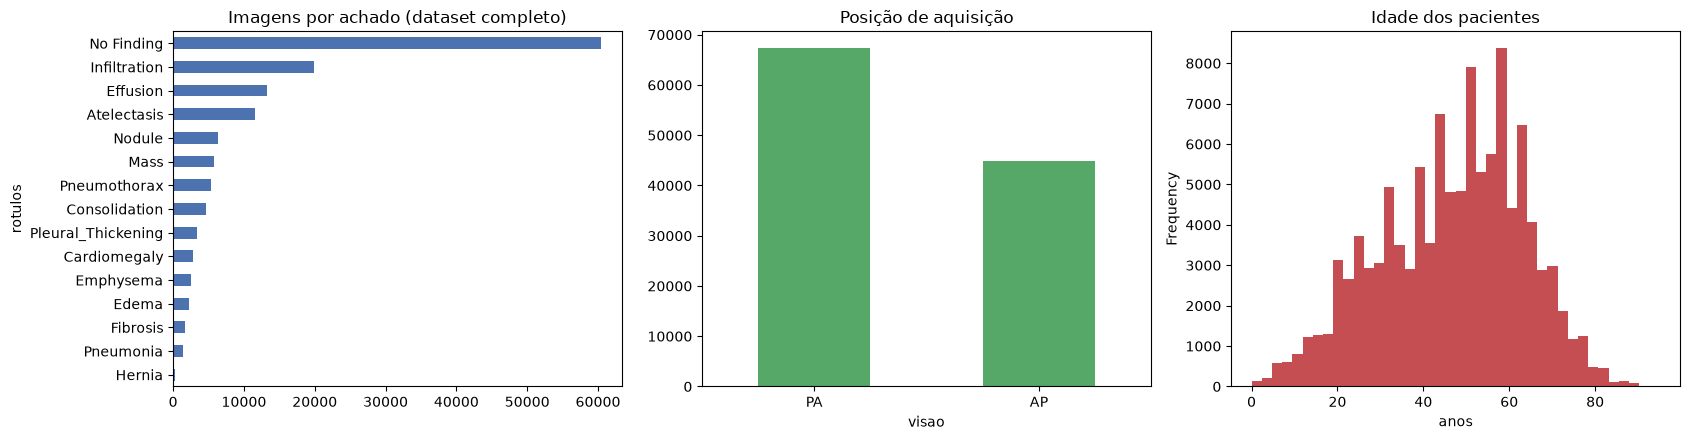

rotulos
No Finding            60361
Infiltration          19894
Effusion              13317
Atelectasis           11559
Nodule                 6331
Mass                   5782
Pneumothorax           5302
Consolidation          4667
Pleural_Thickening     3385
Cardiomegaly           2776
Emphysema              2516
Edema                  2303
Fibrosis               1686
Pneumonia              1431
Hernia                  227

Sexo: {'M': 0.565, 'F': 0.435}
Imagens por paciente: mediana 1.0 | máximo 184


In [3]:
achados = meta.rotulos.str.split("|").explode().value_counts()
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
achados.sort_values().plot.barh(ax=ax[0], color="#4C72B0"); ax[0].set_title("Imagens por achado (dataset completo)")
meta.visao.value_counts().plot.bar(ax=ax[1], color="#55A868", rot=0); ax[1].set_title("Posição de aquisição")
meta.idade.plot.hist(bins=40, ax=ax[2], color="#C44E52"); ax[2].set_title("Idade dos pacientes"); ax[2].set_xlabel("anos")
plt.tight_layout(); plt.savefig(DIR_PRINT / "01_inspecao_dataset.png", dpi=130); plt.show()

print(achados.to_string())
print("\nSexo:", meta.sexo.value_counts(normalize=True).round(3).to_dict())
print("Imagens por paciente: mediana", meta.groupby('paciente').size().median(), "| máximo", meta.groupby('paciente').size().max())

**Leitura da inspeção**

- O dataset é fortemente desbalanceado: "No Finding" domina e Cardiomegalia aparece em menos de 3% das imagens.
- Há muitas imagens por paciente (acompanhamentos). Se imagens do mesmo paciente caírem em treino e em teste, o modelo pode reconhecer o paciente e não a doença. Por isso **a divisão é feita por paciente**.
- A posição de aquisição importa: em AP (paciente geralmente acamado) o coração aparece ampliado na imagem e os pacientes tendem a ser mais graves. Se positivas e negativas tiverem proporções diferentes de AP, a rede pode aprender a diferenciar AP de PA em vez de olhar o coração.

## 4. Recorte do problema e amostragem

**Problema:** classificação binária, Cardiomegalia x Sem achado.

**Classe positiva:** todas as imagens cujo rótulo contém Cardiomegalia, isolada ou combinada com outros achados. Manter as combinadas preserva volume e reflete a prática, em que cardiomegalia costuma vir acompanhada de derrame ou edema.

**Classe negativa:** imagens "No Finding" de pacientes que **nunca** tiveram Cardiomegalia registrada, no máximo uma imagem por paciente (maximiza a diversidade de pacientes), em quantidade igual à da classe positiva.

**Pareamento:** as negativas são sorteadas dentro dos mesmos estratos de posição de aquisição, sexo e faixa etária das positivas. Assim as duas classes ficam com a mesma composição nessas três variáveis e o modelo não consegue usá-las como atalho.

In [4]:
FAIXAS = [0, 18, 40, 60, 200]
ROT_FAIXAS = ["0-17", "18-39", "40-59", "60+"]
meta["faixa"] = pd.cut(meta.idade, bins=FAIXAS, labels=ROT_FAIXAS, right=False).astype(str)
meta["cardio"] = meta.rotulos.str.contains("Cardiomegaly")

pos = meta[meta.cardio].copy()
pac_pos = set(pos.paciente)

# candidatas negativas: Sem achado, paciente sem nenhuma imagem de Cardiomegalia, uma imagem por paciente
cand = meta[(meta.rotulos == "No Finding") & (~meta.paciente.isin(pac_pos))]
cand = cand.sample(frac=1, random_state=SEED).drop_duplicates("paciente")

ESTRATO = ["visao", "sexo", "faixa"]
partes, faltas = [], {}
for chave, g in pos.groupby(ESTRATO):
    disp = cand[(cand.visao == chave[0]) & (cand.sexo == chave[1]) & (cand.faixa == chave[2])]
    n = min(len(g), len(disp))
    if n < len(g): faltas[chave] = len(g) - n
    partes.append(disp.sample(n=n, random_state=SEED))
neg = pd.concat(partes)

# se algum estrato não tiver candidatas suficientes, completa com sorteio simples e registra
if faltas:
    extra = cand.drop(neg.index).sample(n=sum(faltas.values()), random_state=SEED)
    neg = pd.concat([neg, extra])
print("Estratos com falta de candidatas:", faltas if faltas else "nenhum")

pos["classe"], neg["classe"] = "cardiomegalia", "sem_achado"
sub = pd.concat([pos, neg]).reset_index(drop=True)
print("\nSubconjunto:", len(sub), "imagens |", sub.paciente.nunique(), "pacientes")
print(sub.groupby("classe").agg(imagens=("imagem", "count"), pacientes=("paciente", "nunique")))

Estratos com falta de candidatas: nenhum

Subconjunto: 5552 imagens | 4342 pacientes
               imagens  pacientes
classe                           
cardiomegalia     2776       1566
sem_achado        2776       2776


In [5]:
# Conferência do pareamento: a composição das duas classes deve ser igual nas três variáveis
for v in ESTRATO:
    print(pd.crosstab(sub.classe, sub[v], normalize="index").round(3), "\n")
print("Idade média por classe:", sub.groupby("classe").idade.mean().round(1).to_dict())

visao             AP     PA
classe                     
cardiomegalia  0.437  0.563
sem_achado     0.437  0.563 

sexo               F      M
classe                     
cardiomegalia  0.529  0.471
sem_achado     0.529  0.471 

faixa           0-17  18-39  40-59   60+
classe                                  
cardiomegalia  0.054  0.284  0.412  0.25
sem_achado     0.054  0.284  0.412  0.25 

Idade média por classe: {'cardiomegalia': 47.0, 'sem_achado': 46.4}


## 5. Divisão em treino, validação e teste, por paciente

A divisão é feita sobre a lista de **pacientes**, não de imagens, na proporção 70% / 15% / 15%, separadamente para cada classe (estratificação). Todas as imagens de um paciente ficam no mesmo conjunto. A divisão acontece **antes** de qualquer ajuste de modelo, e o conjunto de teste só será usado na avaliação final.

In [6]:
from sklearn.model_selection import train_test_split

pac = sub.groupby("paciente").classe.first().reset_index()
assert sub.groupby("paciente").classe.nunique().max() == 1, "paciente em duas classes"

p_train, p_resto = train_test_split(pac, train_size=FRACOES["train"], stratify=pac.classe, random_state=SEED)
p_val, p_test = train_test_split(p_resto, train_size=0.5, stratify=p_resto.classe, random_state=SEED)
mapa = {**{p: "train" for p in p_train.paciente}, **{p: "val" for p in p_val.paciente}, **{p: "test" for p in p_test.paciente}}
sub["split"] = sub.paciente.map(mapa)

# Verificações de vazamento
conj = {s: set(sub[sub.split == s].paciente) for s in FRACOES}
assert not (conj["train"] & conj["val"]) and not (conj["train"] & conj["test"]) and not (conj["val"] & conj["test"])
assert sub.imagem.is_unique
print("Sem paciente repetido entre conjuntos e sem imagem duplicada.\n")

resumo = pd.crosstab(sub.split, sub.classe, margins=True).loc[["train", "val", "test", "All"]]
resumo["pacientes"] = [len(conj[s]) for s in FRACOES] + [sub.paciente.nunique()]
resumo["% positivas"] = (resumo["cardiomegalia"] / resumo["All"] * 100).round(1)
resumo

Sem paciente repetido entre conjuntos e sem imagem duplicada.



classe,cardiomegalia,sem_achado,All,pacientes,% positivas
split,,,,,
train,1985,1943,3928,3039,50.5
val,389,416,805,651,48.3
test,402,417,819,652,49.1
All,2776,2776,5552,4342,50.0


Como os pacientes com Cardiomegalia têm quantidades diferentes de imagens, a proporção de positivas varia um pouco entre os conjuntos. Isso é esperado na divisão por paciente e é registrado na tabela acima.

## 6. Download seletivo das imagens

O módulo `src/nih_remoto.py` lê apenas o índice dos 12 arquivos zip do dataset e baixa, por requisições HTTP parciais, somente as imagens do subconjunto. O download retoma de onde parou se for interrompido.

In [7]:
import nih_remoto

indice = nih_remoto.construir_indice(DIR_RAW.parent / "indice_zip_nih.json")
print("Imagens no índice:", len(indice))
assert set(sub.imagem) <= set(indice), "há imagens do subconjunto fora do índice"

res = nih_remoto.baixar_imagens(sub.imagem.tolist(), DIR_RAW, indice, n_threads=12)
print("Erros:", res["erro"][:5])
assert not res["erro"], "há imagens com erro de download, execute a célula de novo"
gb = sum((DIR_RAW / n).stat().st_size for n in sub.imagem) / 1e9
print(f"Imagens originais em disco: {len(sub)} arquivos, {gb:.2f} GB")

Imagens no índice: 112120
500/5552 processadas | novas 0 | em cache 500 | erros 0


1000/5552 processadas | novas 0 | em cache 1000 | erros 0


1500/5552 processadas | novas 0 | em cache 1500 | erros 0


2000/5552 processadas | novas 0 | em cache 2000 | erros 0


2500/5552 processadas | novas 0 | em cache 2500 | erros 0


3000/5552 processadas | novas 0 | em cache 3000 | erros 0


... (3 outputs left out)

5000/5552 processadas | novas 0 | em cache 5000 | erros 0


5500/5552 processadas | novas 0 | em cache 5500 | erros 0


5552/5552 processadas | novas 0 | em cache 5552 | erros 0


Erros: []
Imagens originais em disco: 5552 arquivos, 2.20 GB


## 7. Inspeção das imagens originais

Conferimos formato, dimensões e modo de cor em uma amostra, porque isso define as conversões necessárias.

In [8]:
amostra = sub.sample(400, random_state=SEED)
info = []
for n in amostra.imagem:
    with Image.open(DIR_RAW / n) as im:
        info.append((im.size, im.mode, im.format))
info = pd.DataFrame(info, columns=["dimensao", "modo", "formato"])
print(info.value_counts().to_string())

dimensao      modo  formato
(1024, 1024)  L     PNG        398
              RGBA  PNG          2


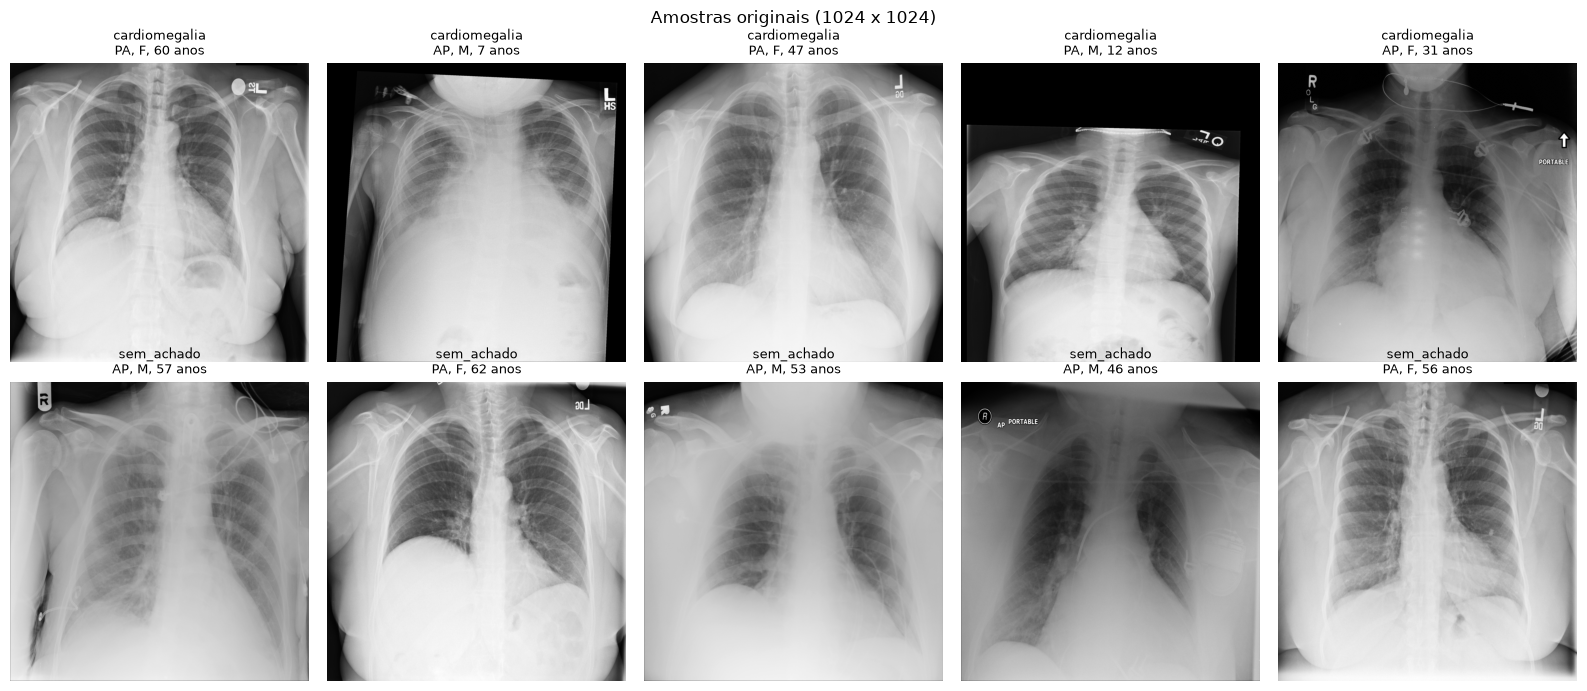

In [9]:
fig, ax = plt.subplots(2, 5, figsize=(16, 7))
for i, c in enumerate(["cardiomegalia", "sem_achado"]):
    for j, (_, r) in enumerate(sub[sub.classe == c].sample(5, random_state=SEED).iterrows()):
        ax[i, j].imshow(Image.open(DIR_RAW / r.imagem).convert("L"), cmap="gray")
        ax[i, j].set_title(f"{c}\n{r.visao}, {r.sexo}, {r.idade} anos", fontsize=9); ax[i, j].axis("off")
plt.suptitle("Amostras originais (1024 x 1024)"); plt.tight_layout()
plt.savefig(DIR_PRINT / "02_amostras_originais.png", dpi=110); plt.show()

## 8. Redimensionamento e conversão de formatos

Para cada imagem:

1. **Conversão para escala de cinza de 8 bits.** Radiografia não tem informação de cor, e parte dos arquivos do NIH vem em RGBA (4 canais). A conversão uniformiza tudo em 1 canal.
2. **Redimensionamento de 1024 x 1024 para 224 x 224** com interpolação por área (`cv2.INTER_AREA`), a mais indicada para redução porque faz a média dos pixels e evita serrilhado. O tamanho 224 é a entrada padrão das redes pré-treinadas vistas em aula (VGG16, ResNet50, MobileNetV2), então a CNN do zero e o Transfer Learning usam exatamente os mesmos dados. Como as imagens originais são quadradas, não há distorção de proporção.
3. **Conversão de PNG para JPEG** (qualidade 95). Reduz o tamanho em disco e acelera a leitura no treino, com perda visual desprezível.
4. **Gravação na estrutura de pastas por conjunto e por classe**, `data/processed/<split>/<classe>/`, a mesma organização usada no Cap 11, lida diretamente pelo `flow_from_directory` do Keras.

A replicação do canal cinza em 3 canais, exigida pelas redes pré-treinadas no ImageNet, é feita na leitura (`color_mode="rgb"`), sem triplicar o tamanho em disco.

In [10]:
from concurrent.futures import ThreadPoolExecutor

def processar(r):
    destino = DIR_PROC / r.split / r.classe / r.imagem.replace(".png", ".jpg")
    if destino.exists(): return 0
    img = cv2.imread(str(DIR_RAW / r.imagem), cv2.IMREAD_UNCHANGED)
    if img is None: return -1
    if img.ndim == 3:                                    # RGBA ou RGB -> cinza
        img = cv2.cvtColor(img, cv2.COLOR_BGRA2GRAY if img.shape[2] == 4 else cv2.COLOR_BGR2GRAY)
    if img.dtype != np.uint8:                            # 16 bits -> 8 bits
        img = cv2.normalize(img, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
    img = cv2.resize(img, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA)
    cv2.imwrite(str(destino), img, [cv2.IMWRITE_JPEG_QUALITY, 95])
    return 1

for s in FRACOES:
    for c in CLASSES: (DIR_PROC / s / c).mkdir(parents=True, exist_ok=True)

with ThreadPoolExecutor(8) as ex:
    r = list(ex.map(processar, [x for x in sub.itertuples()]))
print("Gravadas agora:", r.count(1), "| já existiam:", r.count(0), "| falhas de leitura:", r.count(-1))
assert r.count(-1) == 0

Gravadas agora: 0 | já existiam: 5552 | falhas de leitura: 0


classe  cardiomegalia  sem_achado
split                            
train            1985        1943
val               389         416
test              402         417

Tamanho processado: 71 MB (originais: 2203 MB)


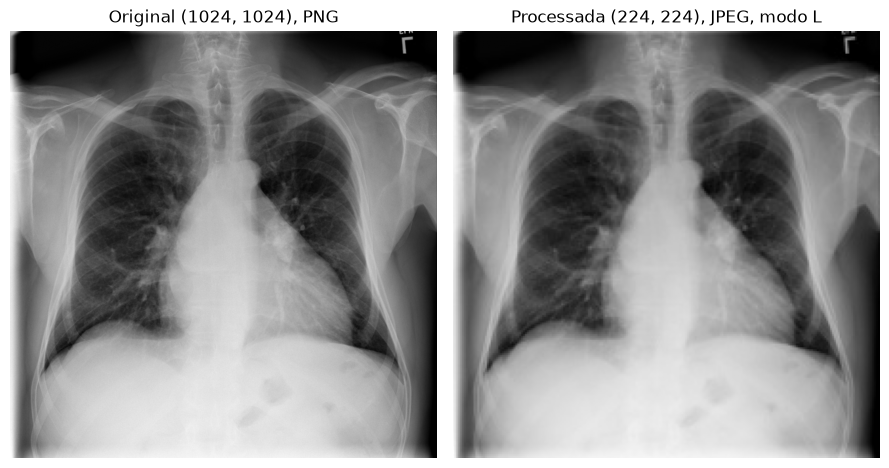

In [11]:
# Conferência do que está em disco contra a tabela planejada
linhas = []
for s in FRACOES:
    for c in CLASSES:
        linhas.append((s, c, len(list((DIR_PROC / s / c).glob("*.jpg")))))
disco = pd.DataFrame(linhas, columns=["split", "classe", "arquivos"]).pivot(index="split", columns="classe", values="arquivos").loc[list(FRACOES)]
print(disco)
assert disco.values.sum() == len(sub)
mb = sum(f.stat().st_size for f in DIR_PROC.rglob("*.jpg")) / 1e6
print(f"\nTamanho processado: {mb:.0f} MB (originais: {gb*1000:.0f} MB)")

ex_ = sub.iloc[0]
orig = Image.open(DIR_RAW / ex_.imagem).convert("L")
proc = Image.open(DIR_PROC / ex_.split / ex_.classe / ex_.imagem.replace(".png", ".jpg"))
fig, ax = plt.subplots(1, 2, figsize=(9, 4.6))
ax[0].imshow(orig, cmap="gray"); ax[0].set_title(f"Original {orig.size}, PNG"); ax[0].axis("off")
ax[1].imshow(proc, cmap="gray"); ax[1].set_title(f"Processada {proc.size}, JPEG, modo {proc.mode}"); ax[1].axis("off")
plt.tight_layout(); plt.savefig(DIR_PRINT / "03_antes_depois.png", dpi=120); plt.show()

## 9. Balanceamento e composição dos conjuntos

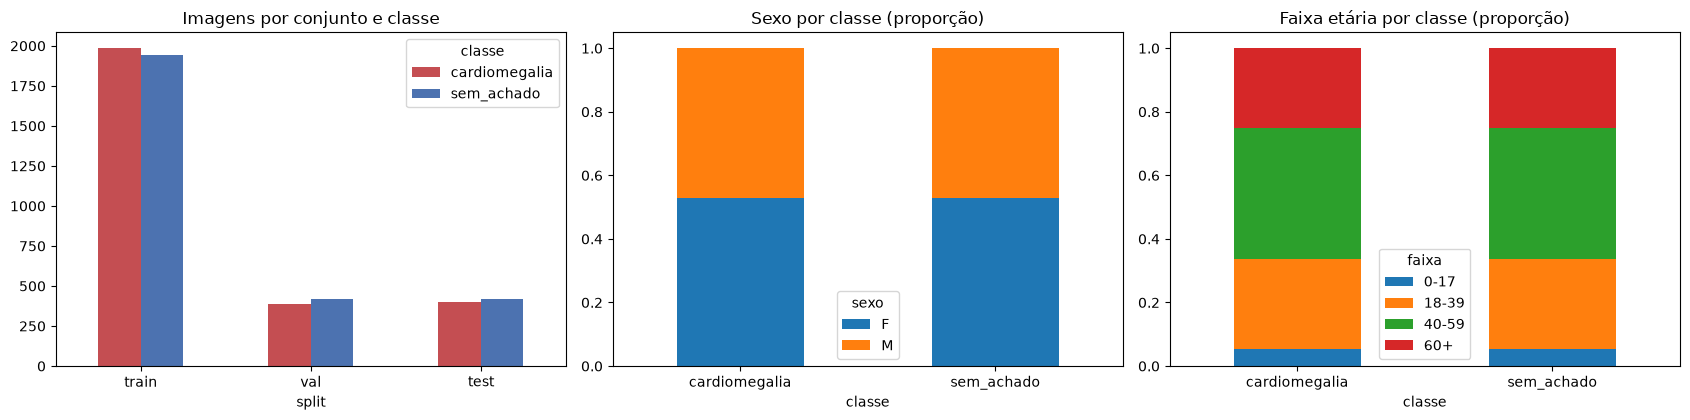

visao                 AP    PA
split classe                  
test  cardiomegalia  192   210
      sem_achado     187   230
train cardiomegalia  872  1113
      sem_achado     847  1096
val   cardiomegalia  149   240
      sem_achado     179   237


In [12]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.3))
pd.crosstab(sub.split, sub.classe).loc[list(FRACOES)].plot.bar(ax=ax[0], rot=0, color=["#C44E52", "#4C72B0"]); ax[0].set_title("Imagens por conjunto e classe")
pd.crosstab(sub.classe, sub.sexo, normalize="index").plot.bar(ax=ax[1], rot=0, stacked=True); ax[1].set_title("Sexo por classe (proporção)")
pd.crosstab(sub.classe, sub.faixa, normalize="index")[ROT_FAIXAS].plot.bar(ax=ax[2], rot=0, stacked=True); ax[2].set_title("Faixa etária por classe (proporção)")
plt.tight_layout(); plt.savefig(DIR_PRINT / "04_balanceamento.png", dpi=130); plt.show()

print(pd.crosstab([sub.split, sub.classe], sub.visao).to_string())

As classes estão balanceadas (1:1 no total), portanto não é preciso ponderar a função de perda nem reamostrar. Vale registrar que esse equilíbrio é **artificial**: na população do dataset a Cardiomegalia aparece em menos de 3% das imagens. As métricas obtidas aqui valem para este cenário balanceado, e valores como a precisão cairiam na prevalência real. Esse ponto volta na avaliação dos modelos.

## 10. Normalização e aumento de dados

**Normalização:** os pixels passam de inteiros em [0, 255] para reais em [0, 1] (`rescale=1/255`). Redes neurais treinam de forma mais estável com entradas em escala pequena e uniforme. A normalização é aplicada na leitura, igual nos três conjuntos.

**Aumento de dados (somente no treino):** pequenas variações geométricas que simulam diferenças reais de posicionamento do paciente: rotação de até 7 graus, deslocamento de até 5% e zoom de até 10%. Validação e teste **não** recebem aumento, pois devem representar imagens reais.

**O que não foi usado e por quê:** espelhamento horizontal. Em fotos comuns ele é inofensivo, mas em radiografia de tórax inverte a anatomia (o coração passaria para o lado direito), criando imagens que não existem na prática para a grande maioria dos pacientes. Rotações grandes também foram evitadas pelo mesmo motivo.

TensorFlow 2.21.0
Found 3928 images belonging to 2 classes.


Found 805 images belonging to 2 classes.


Found 819 images belonging to 2 classes.


Índices das classes: {'sem_achado': 0, 'cardiomegalia': 1}
Lote: (32, 224, 224, 3) float32 | mínimo 0.0 | máximo 1.0 | rótulos: [0. 1. 1. 1. 1. 0. 1. 0.]


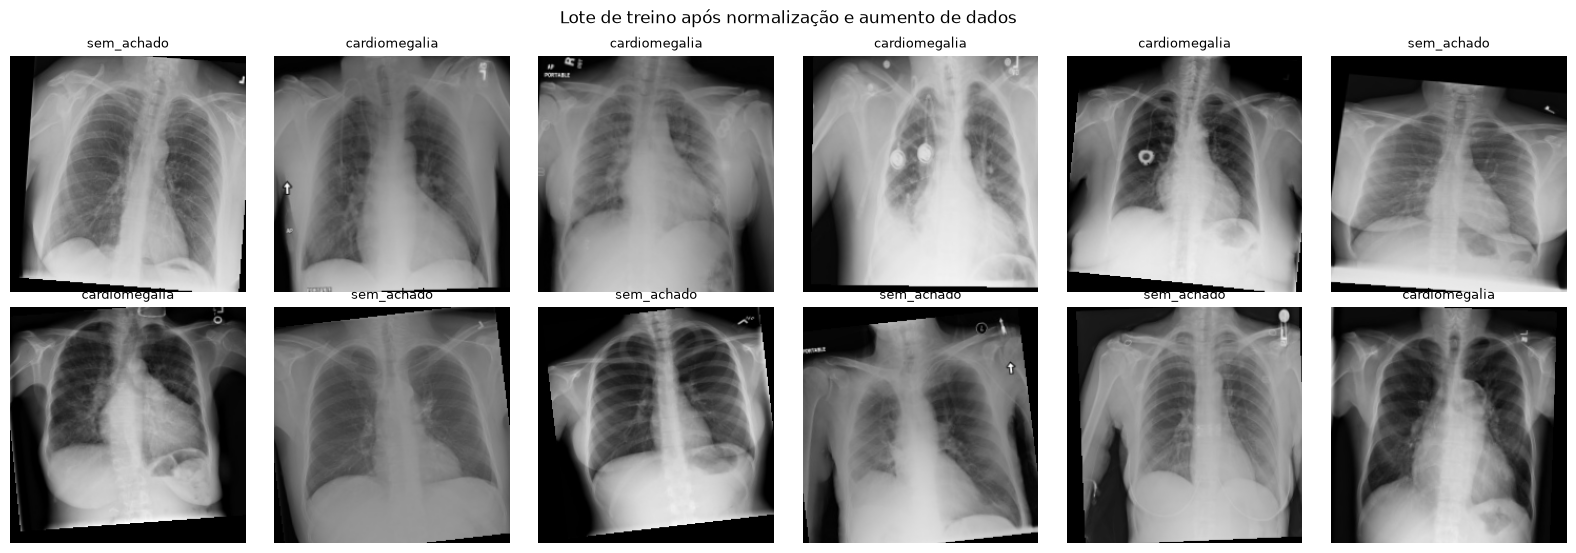

In [13]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
tf.keras.utils.set_random_seed(SEED)
print("TensorFlow", tf.__version__)

BATCH = 32
gen_treino = ImageDataGenerator(rescale=1./255, rotation_range=7, width_shift_range=0.05,
                                height_shift_range=0.05, zoom_range=0.10, fill_mode="constant", cval=0)
gen_aval = ImageDataGenerator(rescale=1./255)

kw = dict(target_size=(IMG_SIZE, IMG_SIZE), color_mode="rgb", class_mode="binary", classes=CLASSES, batch_size=BATCH, seed=SEED)
treino = gen_treino.flow_from_directory(DIR_PROC / "train", shuffle=True, **kw)
val    = gen_aval.flow_from_directory(DIR_PROC / "val", shuffle=False, **kw)
teste  = gen_aval.flow_from_directory(DIR_PROC / "test", shuffle=False, **kw)
print("Índices das classes:", treino.class_indices)

x, y = next(treino)
print("Lote:", x.shape, x.dtype, "| mínimo", float(x.min()), "| máximo", round(float(x.max()), 3), "| rótulos:", y[:8])
assert x.shape == (BATCH, IMG_SIZE, IMG_SIZE, 3) and 0.0 <= x.min() and x.max() <= 1.0
assert np.allclose(x[..., 0], x[..., 1]) and np.allclose(x[..., 1], x[..., 2])   # 3 canais idênticos (cinza replicado)

fig, ax = plt.subplots(2, 6, figsize=(16, 5.6))
for i, a in enumerate(ax.ravel()):
    a.imshow(x[i]); a.set_title(CLASSES[int(y[i])], fontsize=9); a.axis("off")
plt.suptitle("Lote de treino após normalização e aumento de dados"); plt.tight_layout()
plt.savefig(DIR_PRINT / "05_lote_aumentado.png", dpi=110); plt.show()

In [14]:
# Estatísticas de intensidade do conjunto de treino (sem aumento), para referência
arqs = sorted((DIR_PROC / "train").rglob("*.jpg"))
rng = np.random.default_rng(SEED)
am = np.stack([cv2.imread(str(a), cv2.IMREAD_GRAYSCALE) for a in rng.choice(arqs, 1000, replace=False)]) / 255.0
print(f"Treino (amostra de 1000 imagens): média {am.mean():.4f} | desvio padrão {am.std():.4f}")

Treino (amostra de 1000 imagens): média 0.4977 | desvio padrão 0.2498


## 11. Manifesto e resumo

O manifesto registra, para cada imagem, o conjunto, a classe, o paciente e os metadados demográficos. Ele é a base dos notebooks seguintes e da análise de fairness (Ir Além 1), e documenta a origem de cada exemplo.

In [15]:
sub["arquivo"] = sub.apply(lambda r: f"{r.split}/{r.classe}/{r.imagem.replace('.png', '.jpg')}", axis=1)
manifesto = sub[["arquivo", "imagem", "split", "classe", "rotulos", "paciente", "idade", "faixa", "sexo", "visao"]].sort_values(["split", "classe", "imagem"])
manifesto.to_csv(RAIZ / "data" / "manifesto.csv", index=False)

resumo_json = {
    "dataset": "NIH Chest X-ray (ChestX-ray14)", "fonte": "huggingface.co/datasets/alkzar90/NIH-Chest-X-ray-dataset",
    "seed": SEED, "img_size": IMG_SIZE, "classes": CLASSES,
    "total_imagens": int(len(sub)), "total_pacientes": int(sub.paciente.nunique()),
    "por_split": {s: {c: int(((sub.split == s) & (sub.classe == c)).sum()) for c in CLASSES} for s in FRACOES},
    "pacientes_por_split": {s: len(conj[s]) for s in FRACOES},
    "media_treino": round(float(am.mean()), 4), "desvio_treino": round(float(am.std()), 4),
}
(RAIZ / "data" / "resumo_preprocessamento.json").write_text(json.dumps(resumo_json, indent=2, ensure_ascii=False))
print(json.dumps(resumo_json, indent=2, ensure_ascii=False))

{
  "dataset": "NIH Chest X-ray (ChestX-ray14)",
  "fonte": "huggingface.co/datasets/alkzar90/NIH-Chest-X-ray-dataset",
  "seed": 42,
  "img_size": 224,
  "classes": [
    "sem_achado",
    "cardiomegalia"
  ],
  "total_imagens": 5552,
  "total_pacientes": 4342,
  "por_split": {
    "train": {
      "sem_achado": 1943,
      "cardiomegalia": 1985
    },
    "val": {
      "sem_achado": 416,
      "cardiomegalia": 389
    },
    "test": {
      "sem_achado": 417,
      "cardiomegalia": 402
    }
  },
  "pacientes_por_split": {
    "train": 3039,
    "val": 651,
    "test": 652
  },
  "media_treino": 0.4977,
  "desvio_treino": 0.2498
}


## Conclusão da Parte 1

O pipeline entrega um conjunto balanceado de radiografias de tórax, dividido por paciente em treino, validação e teste, redimensionado para 224 x 224, convertido para JPEG em escala de cinza e organizado em pastas por classe. A normalização para [0, 1] e o aumento de dados (apenas no treino) são aplicados na leitura. Os próximos notebooks (`02_cnn_do_zero` e `03_transfer_learning`) consomem exatamente estas pastas.

**Limitações registradas:** rótulos obtidos por mineração de texto (com ruído), balanceamento artificial em relação à prevalência real, dataset de um único hospital dos Estados Unidos e perda de detalhe fino na redução para 224 pixels.

**Referência:** Wang X, Peng Y, Lu L, Lu Z, Bagheri M, Summers RM. ChestX-ray8: Hospital-scale Chest X-ray Database and Benchmarks on Weakly-Supervised Classification and Localization of Common Thorax Diseases. IEEE CVPR 2017. Dados fornecidos pelo NIH Clinical Center, disponíveis em https://nihcc.app.box.com/v/ChestXray-NIHCC.